# 01 – Veri İnceleme (EDA)

**Proje:** Büyük Dil Modellerinde Yanlış Bilgi Üretiminin Otomatik Tespiti
**Ders:** YMÜ425 – Uygulamalı Sinir Ağları

Bu notebook'ta:
1. HaluEval QA verisini indiriyoruz,
2. İkili sınıflandırma veri setine dönüştürüyoruz,
3. Veri kalitesini kontrol ediyoruz (eksik / tekrarlı veri),
4. Uzunluk dağılımlarını inceliyoruz ve **bir kısayolu** ortaya çıkarıyoruz,
5. Veriyi **soru bazlı** olarak eğitim / doğrulama / test kümelerine ayırıyoruz.

> Yönergede karşılığı: Bölüm 5 (Veri seti), 6 (İnceleme ve ön işleme), 7 (Eğitim/doğrulama/test).

## 0. Kurulum

Colab'da çalışıyorsak repoyu klonlayıp içine giriyoruz. Kendi bilgisayarımızda repo içinden açtıysak bu adım atlanır.

👉 `REPO_URL` satırını kendi GitHub adresinizle değiştirin.

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/KULLANICI_ADI/llm-halusinasyon-tespiti.git"  # <-- değiştir

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # yerelde: repo köküne çık
elif not os.path.exists("src"):         # Colab: repoyu klonla
    subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir("llm-halusinasyon-tespiti")

sys.path.insert(0, os.getcwd())
os.makedirs("results/figures", exist_ok=True)
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/llm-halusinasyon-tespiti


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_halueval_qa, to_binary_frame, group_split, SEED

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
np.random.seed(SEED)

## 1. Veriyi Yükleme

HaluEval (Li ve ark., 2023) QA kümesinde **10.000 soru** var. Her satırda 4 alan bulunuyor:

| Alan | Anlamı |
|---|---|
| `knowledge` | Kaynak metin (Wikipedia'dan, HotpotQA veri setinden) |
| `question` | Soru |
| `right_answer` | Kaynakla tutarlı doğru cevap |
| `hallucinated_answer` | ChatGPT'ye bilerek ürettirilmiş, kaynakla **tutarsız** cevap |

In [3]:
rows = load_halueval_qa("data/qa_data.json")
print("Soru sayısı:", len(rows))
print("Alanlar:", list(rows[0].keys()))
rows[0]

Soru sayısı: 10000
Alanlar: ['knowledge', 'question', 'right_answer', 'hallucinated_answer']


{'knowledge': "Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century.First for Women is a woman's magazine published by Bauer Media Group in the USA.",
 'question': "Which magazine was started first Arthur's Magazine or First for Women?",
 'right_answer': "Arthur's Magazine",
 'hallucinated_answer': 'First for Women was started first.'}

## 2. İkili Sınıflandırma Formatına Dönüştürme

Her soruyu **iki örneğe** açıyoruz:
- `(kaynak, soru, doğru cevap)` → **etiket 0** (destekleniyor)
- `(kaynak, soru, halüsinasyonlu cevap)` → **etiket 1** (halüsinasyon)

`qid` sütunu aynı soruya ait iki örneği birbirine bağlıyor. Bölme sırasında bu sütunu kullanacağız.

In [4]:
df = to_binary_frame(rows)
print(df.shape)
df.head(4)

(20000, 5)


,qid,knowledge,question,answer,label
0,0,Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century.Firs...,Which magazine was started first Arthur's Magazine or First for Women?,Arthur's Magazine,0
1,0,Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century.Firs...,Which magazine was started first Arthur's Magazine or First for Women?,First for Women was started first.,1
2,1,"The Oberoi family is an Indian family that is famous for its involvement in hotels, namely through The Oberoi Group....",The Oberoi family is part of a hotel company that has a head office in what city?,Delhi,0
3,1,"The Oberoi family is an Indian family that is famous for its involvement in hotels, namely through The Oberoi Group....",The Oberoi family is part of a hotel company that has a head office in what city?,The Oberoi family's hotel company is based in Mumbai.,1


## 3. Veri Kalitesi Kontrolleri

Yönerge md. 6: eksik, hatalı ve tekrarlı verilerin kontrol edilmesi.

In [5]:
print("Eksik değer sayısı:\n", df.isna().sum(), "\n")

bos = (df[["knowledge", "question", "answer"]].apply(lambda s: s.str.strip() == "")).sum()
print("Boş metin sayısı:\n", bos, "\n")

print("Tekrarlı soru metni:", df.drop_duplicates("qid")["question"].duplicated().sum())
print("Tekrarlı (soru, cevap) çifti:", df.duplicated(["question", "answer"]).sum())

ayni = sum(r["right_answer"].strip().lower() == r["hallucinated_answer"].strip().lower() for r in rows)
print("Doğru ve halüsinasyonlu cevabı aynı olan soru:", ayni)

Eksik değer sayısı:
 qid          0
knowledge    0
question     0
answer       0
label        0
dtype: int64 

Boş metin sayısı:
 knowledge    0
question     0
answer       0
dtype: int64 

Tekrarlı soru metni: 0
Tekrarlı (soru, cevap) çifti: 0
Doğru ve halüsinasyonlu cevabı aynı olan soru: 0


## 4. Sınıf Dağılımı

Her sorudan bir doğru ve bir yanlış cevap aldığımız için sınıflar **tam dengeli** (%50 / %50). Bu yüzden ek bir sınıf ağırlıklandırmaya ihtiyaç yok.

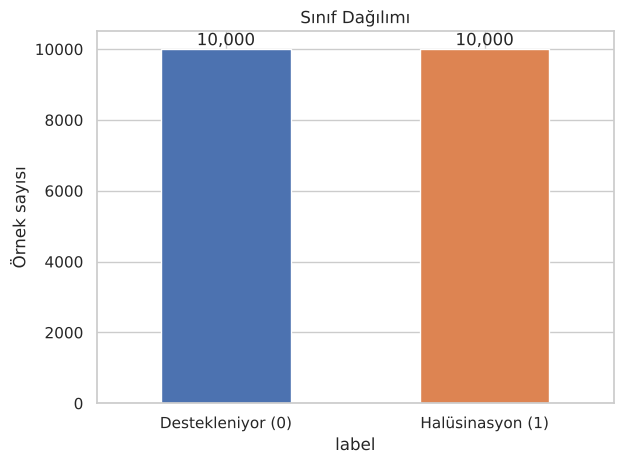

In [6]:
ax = df["label"].map({0: "Destekleniyor (0)", 1: "Halüsinasyon (1)"}).value_counts().plot.bar(rot=0, color=["#4C72B0", "#DD8452"])
ax.set_title("Sınıf Dağılımı"); ax.set_ylabel("Örnek sayısı")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig("results/figures/01_sinif_dagilimi.png", dpi=150); plt.show()

## 5. Uzunluk Analizi — Önemli Bulgu ⚠️

Kelime sayılarına bakıyoruz: kaynak metin, soru ve cevap.

In [7]:
for col in ["knowledge", "question", "answer"]:
    df[f"{col}_len"] = df[col].str.split().str.len()

df.groupby("label")["answer_len"].describe().rename(index={0: "Destekleniyor", 1: "Halüsinasyon"}).round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Destekleniyor,10000.0,2.22,1.84,1.0,1.0,2.0,3.0,81.0
Halüsinasyon,10000.0,10.99,6.15,1.0,6.0,9.0,14.0,61.0


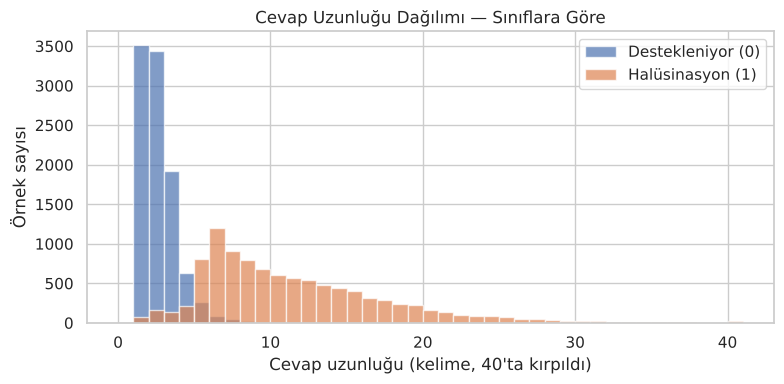

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
clip = df["answer_len"].clip(upper=40)
ax.hist(clip[df.label == 0], bins=range(0, 42), alpha=0.7, label="Destekleniyor (0)", color="#4C72B0")
ax.hist(clip[df.label == 1], bins=range(0, 42), alpha=0.7, label="Halüsinasyon (1)", color="#DD8452")
ax.set_xlabel("Cevap uzunluğu (kelime, 40'ta kırpıldı)"); ax.set_ylabel("Örnek sayısı")
ax.set_title("Cevap Uzunluğu Dağılımı — Sınıflara Göre"); ax.legend()
plt.tight_layout(); plt.savefig("results/figures/01_cevap_uzunlugu.png", dpi=150); plt.show()

In [9]:
pair = df.pivot(index="qid", columns="label", values="answer_len")
daha_uzun = (pair[1] > pair[0]).mean()
print(f"Halüsinasyonlu cevabın doğru cevaptan UZUN olduğu soruların oranı: %{daha_uzun*100:.1f}")

Halüsinasyonlu cevabın doğru cevaptan UZUN olduğu soruların oranı: %95.8


**Yorum:** Doğru cevaplar genellikle kısa bir varlık adı (örn. *"Arthur's Magazine"*), halüsinasyonlu cevaplar ise tam cümle (örn. *"First for Women was started first."*). Sebebi veri üretim süreci: halüsinasyonlu cevaplar ChatGPT'ye cümle hâlinde ürettirilmiş.

**Neden önemli?** Bir model kaynak metni hiç okumadan, sadece cevabın uzunluğuna bakarak yüksek başarı elde edebilir. Buna **kısayol öğrenme (shortcut learning)** denir. Aşağıda bunu hızlıca test ediyoruz.

## 6. Kaynak Metin Uzunluğu — Model Girdisine Sığıyor mu?

BERT ve DeBERTa en fazla **512 token** alır. Girdi `[CLS] kaynak [SEP] soru + cevap [SEP]` şeklinde olacak. Kabaca 1 İngilizce kelime ≈ 1,3 token.

count    20000.0
mean       104.0
std         34.4
min         31.0
25%         78.0
50%         99.0
75%        124.0
max        382.0
Name: tahmini_token, dtype: float64

512 token'ı aşma ihtimali olan örnek oranı: %0.00


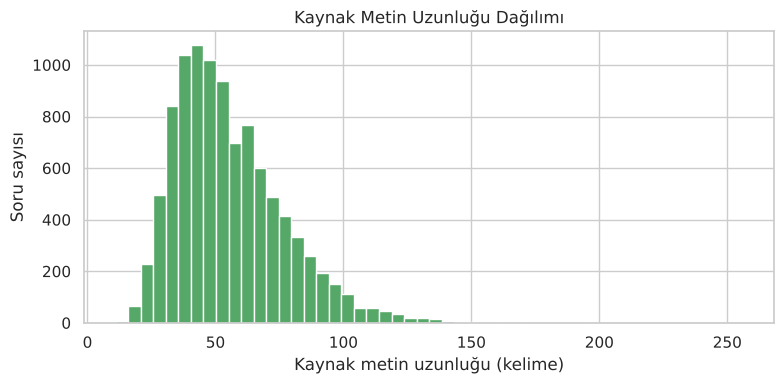

In [10]:
df["girdi_kelime"] = df["knowledge_len"] + df["question_len"] + df["answer_len"]
df["tahmini_token"] = (df["girdi_kelime"] * 1.3).round()
print(df["tahmini_token"].describe().round(1))
print(f"\n512 token'ı aşma ihtimali olan örnek oranı: %{(df['tahmini_token'] > 512).mean()*100:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df.drop_duplicates("qid")["knowledge_len"], bins=50, color="#55A868")
ax.set_xlabel("Kaynak metin uzunluğu (kelime)"); ax.set_ylabel("Soru sayısı")
ax.set_title("Kaynak Metin Uzunluğu Dağılımı")
plt.tight_layout(); plt.savefig("results/figures/01_kaynak_uzunlugu.png", dpi=150); plt.show()

## 7. Soru Bazlı Veri Bölme (Veri Sızıntısı Önlemi)

**Neden rastgele bölmüyoruz?** Rastgele bölmede aynı sorunun doğru cevabı eğitim kümesine, yanlış cevabı test kümesine düşebilir. Model eğitimde soruyu ve kaynağı görmüş olur, testte bu avantajı kullanır ve başarı olduğundan yüksek ölçülür.

**Çözüm:** `GroupShuffleSplit` ile `qid` üzerinden gruplu bölme. Böylece bir sorunun iki cevabı her zaman **aynı** kümede kalır.

Oranlar: %70 eğitim / %15 doğrulama / %15 test, `random_state=42`.

In [11]:
train, val, test = group_split(df)

ozet = pd.DataFrame({
    "Küme": ["Eğitim", "Doğrulama", "Test"],
    "Soru sayısı": [k.qid.nunique() for k in (train, val, test)],
    "Örnek sayısı": [len(k) for k in (train, val, test)],
    "Halüsinasyon oranı": [round(k.label.mean(), 3) for k in (train, val, test)],
})
print("Sızıntı kontrolü geçti ✓ (ortak soru yok)")
ozet

Sızıntı kontrolü geçti ✓ (ortak soru yok)


,Küme,Soru sayısı,Örnek sayısı,Halüsinasyon oranı
0,Eğitim,7000,14000,0.5
1,Doğrulama,1500,3000,0.5
2,Test,1500,3000,0.5


In [12]:
os.makedirs("data/processed", exist_ok=True)
cols = ["qid", "knowledge", "question", "answer", "label"]
train[cols].to_csv("data/processed/train.csv", index=False)
val[cols].to_csv("data/processed/val.csv", index=False)
test[cols].to_csv("data/processed/test.csv", index=False)
ozet.to_csv("results/01_bolme_ozeti.csv", index=False)
print("Kaydedildi: data/processed/{train,val,test}.csv")

Kaydedildi: data/processed/{train,val,test}.csv


## 8. Ön Deney: Sadece Uzunlukla Ne Kadar Başarı Elde Edilir?

Kaynak metni **hiç kullanmadan**, yalnızca cevabın kelime sayısını özellik alan bir Lojistik Regresyon eğitiyoruz. Eğitim kümesinde eğitip doğrulama kümesinde ölçüyoruz. Test kümesine dokunmuyoruz, o en sona kalacak.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score

X_tr, y_tr = train[["answer_len"]], train["label"]
X_va, y_va = val[["answer_len"]], val["label"]

lr = LogisticRegression().fit(X_tr, y_tr)
p = lr.predict_proba(X_va)[:, 1]
yhat = (p >= 0.5).astype(int)

print(f"Sadece-uzunluk modeli (doğrulama):")
print(f"  Accuracy: {accuracy_score(y_va, yhat):.3f}")
print(f"  F1      : {f1_score(y_va, yhat):.3f}")
print(f"  ROC-AUC : {roc_auc_score(y_va, p):.3f}")

Sadece-uzunluk modeli (doğrulama):
  Accuracy: 0.943
  F1      : 0.943


  ROC-AUC : 0.973


**Sonuç:** Kaynak metni hiç okumayan bir model bile çok yüksek skor alıyor. Bu yüzden:

1. Bu modeli projemizde **"kısayol baseline"** olarak raporlayacağız. Sinir ağı modellerimiz anlamlı olmak için en azından bunu geçmeli.
2. **Uzunluğu eşitlenmiş bir test kümesi** oluşturacağız. Bu kümede iki sınıfın cevap uzunlukları benzer olacak. Gerçek başarıyı orada ölçeceğiz.
3. Bu durum projemizin **özgün değeri**: HaluEval üzerinde raporlanan yüksek skorların ne kadarının gerçek "kaynakla tutarlılık" öğrenmesinden geldiğini sorguluyoruz.

## 9. Örnekler

In [14]:
for qid in train.qid.drop_duplicates().sample(3, random_state=SEED):
    s = df[df.qid == qid]
    print("KAYNAK :", s.knowledge.iloc[0][:300], "...")
    print("SORU   :", s.question.iloc[0])
    print("DOĞRU  :", s[s.label == 0].answer.iloc[0])
    print("HALÜS. :", s[s.label == 1].answer.iloc[0])
    print("-" * 100)

KAYNAK : Billings Logan International Airport (IATA: BIL, ICAO: KBIL, FAA LID: BIL) is two miles northwest of downtown Billings, in Yellowstone County, Montana.Palm Springs International Airport (IATA: PSP, ICAO: KPSP, FAA LID: PSP) , formerly Palm Springs Municipal Airport, is a public airport two miles (3  ...
SORU   : Billings Logan International Airport and Palm Springs International Airport, both are located in the US?
DOĞRU  : yes
HALÜS. : Billings Logan International Airport is located in Montana, while Palm Springs International Airport is located in California in the United States.
----------------------------------------------------------------------------------------------------
KAYNAK :  The region also oversees installation support for the Pacific Missile Range Facility, the world's largest instrumented, multi-dimensional testing and training missile range in Kekaha, Hawaii.The Pacific Missile Range Facility, Barking Sands (IATA: BKH, ICAO: PHBK, FAA LID: BKH) is a U.S. na

## 10. Bulguların Özeti

| Bulgu | Değer / Yorum |
|---|---|
| Toplam örnek | 20.000 (10.000 soru × 2 cevap) |
| Sınıf dengesi | %50 / %50, sınıf ağırlıklandırma gerekmiyor |
| Eksik / boş veri | Yukarıdaki çıktıya bakın |
| Girdi uzunluğu | Neredeyse tamamı 512 token sınırına sığıyor |
| **Uzunluk kısayolu** | Halüsinasyonlu cevaplar çok daha uzun. Sadece uzunluğa bakan model çok yüksek skor alıyor |
| Bölme | Soru bazlı %70/15/15, sızıntı kontrolü geçti |

## Savunmada Sorulabilecek Sorular (herkes cevaplayabilmeli!)

1. **Neden rastgele değil de soru bazlı böldünüz?** → Aynı sorunun iki cevabı farklı kümelere düşerse veri sızıntısı olur.
2. **Sınıf dengesizliği var mı?** → Yok, her sorudan bir doğru ve bir yanlış cevap var.
3. **Uzunluk kısayolu nedir, neden sorun?** → Model anlamı değil, yüzeysel bir ipucunu öğrenir. Gerçek hayattaki LLM çıktılarında bu ipucu olmayabilir, model orada başarısız olur.
4. **Test kümesini ne zaman kullanıyorsunuz?** → Sadece en sonda, final değerlendirmede. Model ve hiperparametre seçimi doğrulama kümesiyle yapılır.
5. **512 token sınırı sorun mu?** → Bu veri setinde değil, girdiler kısa.

**Sonraki adım:** `02_baselines.ipynb` — TF-IDF + Lojistik Regresyon ve uzunluğu eşitlenmiş test kümesi.